# Neural Network Challenger: Is a Network Worth It for Kickstarter?

This notebook extends [`04_kickstarter-success.ipynb`](04_kickstarter-success.ipynb). It builds **one reasonable neural network**, compares it fairly with the tuned gradient boosting model from notebook 04 (the *historical baseline*), and collects the evidence for [`model-comparison-report.md`](model-comparison-report.md) and [`decision-memo.md`](decision-memo.md).

The rules of the comparison were fixed **before** training in [`model-comparison-plan.md`](model-comparison-plan.md):

- the same 66,335 test campaigns and the same primary metric (ROC-AUC);
- the network must beat the baseline by **at least +0.005 ROC-AUC**, on average and in its worst seed;
- the same tuning budget (12 configurations) and 5 repeated seeds for the final network;
- thresholds, early stopping and configuration choice use validation data only;
- hard constraints: below 100 ms per prediction on a CPU laptop, and a higher goal must never raise the predicted chance.

## Setup

`SMOKE_TEST` shortens every loop so that the whole notebook can be checked in a minute. It must be `False` for the reported results.

In [1]:
import hashlib
import os
import platform
import time
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")  # hide TensorFlow info messages

import joblib
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.base import clone
import tensorflow as tf
tf.get_logger().setLevel("ERROR")  # hide harmless retracing warnings
from keras import layers, regularizers
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score, brier_score_loss, confusion_matrix, f1_score, log_loss,
    precision_recall_curve, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

SMOKE_TEST = os.environ.get("SMOKE_TEST") == "1"

DATA_PATH = Path("data/ks-projects-201801.csv")
HGB_PATH = Path("models/kickstarter_hgb.joblib")                    # stale file, see below
HGB_REBUILT_PATH = Path("models/kickstarter_hgb_rebuilt.joblib")
NN_PATH = Path("models/kickstarter_nn.keras")
NN_PREP_PATH = Path("models/kickstarter_nn_preprocessing.joblib")
RANDOM_STATE = 42

N_TRIALS = 2 if SMOKE_TEST else 12          # tuning budget (same as notebook 04)
MAX_EPOCHS = 2 if SMOKE_TEST else 30
PATIENCE = 3
SEEDS = [0, 1] if SMOKE_TEST else [0, 1, 2, 3, 4]
N_BOOTSTRAP = 20 if SMOKE_TEST else 300
TIMING_REPEATS, TIMING_WARMUP = (3, 1) if SMOKE_TEST else (20, 3)

SUCCESS_COLOR, FAIL_COLOR, NEUTRAL_COLOR, NN_COLOR = "#2a78d6", "#eb6834", "#8a8986", "#1baf7a"
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False})

print("SMOKE_TEST:", SMOKE_TEST)
print("Python", platform.python_version(), "| scikit-learn", sklearn.__version__,
      "| TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("CPU:", platform.processor(), "| logical cores:", os.cpu_count(),
      "| GPUs visible to TensorFlow:", len(tf.config.list_physical_devices("GPU")))

SMOKE_TEST: False
Python 3.13.15 | scikit-learn 1.9.0 | TensorFlow 2.21.0 | Keras 3.15.1
CPU: Intel64 Family 6 Model 140 Stepping 1, GenuineIntel | logical cores: 4 | GPUs visible to TensorFlow: 0


## Recreate the Same Data and Test Set

We repeat the cleaning and feature steps of notebook 04 **exactly** (same code, same `random_state`). Then we check that the test rows are identical to `data/X_test.csv`, which notebook 04 saved. If even one row differed, the comparison would not be fair and the notebook stops.

In [2]:
sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print("Dataset SHA-256:", sha256)

kickstarter = pd.read_csv(DATA_PATH, parse_dates=["deadline", "launched"])
kickstarter = kickstarter[kickstarter["state"].isin(["successful", "failed"])].copy()
kickstarter["success"] = (kickstarter["state"] == "successful").astype(int)
kickstarter = kickstarter.drop(
    columns=["pledged", "usd pledged", "usd_pledged_real", "backers", "state", "ID", "goal"]
)
kickstarter["country"] = kickstarter["country"].replace('N,0"', "Unknown")
kickstarter["name"] = kickstarter["name"].fillna("")

name = kickstarter["name"]
kickstarter["log_goal"] = np.log1p(kickstarter["usd_goal_real"])
kickstarter["duration_days"] = (
    kickstarter["deadline"] - kickstarter["launched"].dt.normalize()
).dt.days
kickstarter["launch_year"] = kickstarter["launched"].dt.year
kickstarter["launch_month"] = kickstarter["launched"].dt.month
kickstarter["launch_weekday"] = kickstarter["launched"].dt.dayofweek
kickstarter["launch_hour"] = kickstarter["launched"].dt.hour
kickstarter["name_words"] = name.str.split().str.len()
kickstarter["name_chars"] = name.str.len()
kickstarter["name_has_exclaim"] = name.str.contains("!", regex=False).astype(int)
kickstarter["name_has_question"] = name.str.contains("?", regex=False).astype(int)
kickstarter["name_upper_words"] = name.str.count(r"\b[A-Z]{2,}\b")

CATEGORICAL = ["main_category", "category", "country", "currency"]
NUMERIC = [
    "log_goal", "duration_days", "launch_year", "launch_month", "launch_weekday",
    "launch_hour", "name_words", "name_chars", "name_has_exclaim",
    "name_has_question", "name_upper_words",
]
FEATURES = CATEGORICAL + NUMERIC

y = kickstarter["success"]
X = kickstarter[CATEGORICAL + NUMERIC + ["usd_goal_real"]]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

saved_test_index = pd.read_csv("data/X_test.csv", index_col=0).index
assert X_test.index.equals(saved_test_index), "Test rows differ from notebook 04!"
print(f"Train: {len(X_train):,} rows | Test: {len(X_test):,} rows (identical to data/X_test.csv)")

Dataset SHA-256: 4846177ce8cfacd06a6acf06cba663b9aa5f5f77e7d0debecf5bdc861a87e3cb


Train: 265,340 rows | Test: 66,335 rows (identical to data/X_test.csv)


## Split Off a Validation Set

The network needs data to decide **when to stop training** (early stopping), **which settings are best**, and **which threshold to use**. None of these decisions may look at the test set. So we split the training set once more: 85% to fit the weights, 15% for validation.

In [3]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.15, stratify=y_train, random_state=RANDOM_STATE
)
print(f"Fit: {len(X_fit):,} | Validation: {len(X_val):,} | Test (untouched): {len(X_test):,}")

Fit: 225,539 | Validation: 39,801 | Test (untouched): 66,335


## Prepare the Inputs for a Network

Trees can work with raw numbers, but networks learn best when inputs are on similar scales. Model-specific preprocessing is allowed in a fair comparison, as long as it is learned on training data only:

- **Numbers** are standardised (mean 0, standard deviation 1). The scaler is fitted on the fit set only.
- **Categories** become integer codes, and the network learns an **embedding** for each one: a short list of numbers that places similar categories close together. For example, it can learn that *Tabletop Games* behaves more like *Comics* than like *Apps*. Code 0 is reserved for categories never seen in training.

In [4]:
class NNPreprocessor:
    # Turns a feature DataFrame into the dict of arrays the Keras model expects.

    def fit(self, X):
        self.encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit(X[CATEGORICAL])
        self.scaler = StandardScaler().fit(X[NUMERIC])
        self.vocab_sizes = {col: len(cats) + 1 for col, cats in zip(CATEGORICAL, self.encoder.categories_)}
        return self

    def transform(self, X):
        codes = self.encoder.transform(X[CATEGORICAL]).astype("int32") + 1  # unknown -> 0
        inputs = {col: codes[:, [i]] for i, col in enumerate(CATEGORICAL)}
        inputs["numeric"] = self.scaler.transform(X[NUMERIC]).astype("float32")
        return inputs


prep = NNPreprocessor().fit(X_fit)
fit_inputs, val_inputs, test_inputs = (prep.transform(d) for d in (X_fit, X_val, X_test))
y_fit_arr, y_val_arr = y_fit.to_numpy("float32"), y_val.to_numpy("float32")
print("Category vocabulary sizes (incl. unknown):", prep.vocab_sizes)

Category vocabulary sizes (incl. unknown): {'main_category': 16, 'category': 160, 'country': 24, 'currency': 15}


## The Network

We use the simplest architecture that fits tabular data: a **small feed-forward network**.

1. Each categorical column goes through its own embedding layer.
2. The embeddings and the standardised numbers are joined into one vector.
3. One to three dense (fully connected) layers with ReLU activation learn combinations of the inputs. Dropout and L2 regularisation fight over-fitting.
4. One output neuron with a sigmoid gives the success probability (0 to 1).

There is no CNN, RNN or transformer. The inputs are a table, not images, text or sequences, so those would add complexity without a reason.

In [5]:
def build_model(cfg, seed):
    keras.utils.set_random_seed(seed)  # seeds Python, NumPy and TensorFlow
    inputs, parts = {}, []
    for col in CATEGORICAL:
        inp = keras.Input(shape=(1,), dtype="int32", name=col)
        dim = min(cfg["emb_dim"], prep.vocab_sizes[col] - 1)
        parts.append(layers.Flatten()(layers.Embedding(prep.vocab_sizes[col], dim, name=f"{col}_embedding")(inp)))
        inputs[col] = inp
    inputs["numeric"] = keras.Input(shape=(len(NUMERIC),), name="numeric")
    x = layers.Concatenate()(parts + [inputs["numeric"]])
    for _ in range(cfg["depth"]):
        x = layers.Dense(cfg["width"], activation="relu", kernel_regularizer=regularizers.l2(cfg["l2"]))(x)
        if cfg["dropout"] > 0:
            x = layers.Dropout(cfg["dropout"])(x)
    output = layers.Dense(1, activation="sigmoid", name="success_probability")(x)
    model = keras.Model(inputs, output)
    model.compile(
        optimizer=keras.optimizers.Adam(cfg["learning_rate"]),
        loss="binary_crossentropy",
        metrics=[keras.metrics.AUC(name="auc")],
    )
    return model


def train(cfg, seed):
    # Fit with early stopping on validation ROC-AUC; return model, val probabilities, epochs, seconds.
    model = build_model(cfg, seed)
    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_auc", mode="max", patience=PATIENCE, restore_best_weights=True
    )
    start = time.perf_counter()
    history = model.fit(
        fit_inputs, y_fit_arr, validation_data=(val_inputs, y_val_arr),
        epochs=MAX_EPOCHS, batch_size=cfg["batch_size"], callbacks=[early_stopping], verbose=0,
    )
    seconds = time.perf_counter() - start
    val_proba = model.predict(val_inputs, batch_size=8192, verbose=0).ravel()
    return model, val_proba, len(history.history["loss"]), seconds


example_cfg = dict(width=128, depth=2, dropout=0.1, l2=1e-5, emb_dim=8, learning_rate=1e-3, batch_size=1024)
build_model(example_cfg, seed=0).summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ main_category       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ category            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ country             │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ currency            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ main_category_embe… │ (None, 1, 8)      │        128 │ main_category[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ category_embedding  │ (None, 1, 8)      │      1,280 │ category[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ country_embedding   │ (None, 1, 8)      │        192 │ country[0][0]     │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ currency_embedding  │ (None, 1, 8)      │        120 │ currency[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 8)         │          0 │ main_category_em… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 8)         │          0 │ category_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_2 (Flatten) │ (None, 8)         │          0 │ country_embeddin… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_3 (Flatten) │ (None, 8)         │          0 │ currency_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ numeric             │ (None, 11)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 43)        │          0 │ flatten[0][0],    │
│ (Concatenate)       │                   │            │ flatten_1[0][0],  │
│                     │                   │            │ flatten_2[0][0],  │
│                     │                   │            │ flatten_3[0][0],  │
│                     │                   │            │ numeric[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │      5,632 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     16,512 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 23,993 (93.72 KB)

 Trainable params: 23,993 (93.72 KB)

 Non-trainable params: 0 (0.00 B)

## Tune with the Same Budget as the Baseline

Notebook 04 tried **12 random combinations** for gradient boosting. The network gets the same budget: 12 random combinations of the settings below. Each is trained on the fit set and judged on the **validation** set. The test set is not used.

| Setting | Meaning | Options |
| --- | --- | --- |
| `width` | neurons per hidden layer | 64, 128, 256 |
| `depth` | number of hidden layers | 1, 2, 3 |
| `dropout` | share of neurons switched off randomly during training | 0, 0.1, 0.2, 0.3 |
| `l2` | penalty on large weights | 0, 1e-5, 1e-4 |
| `emb_dim` | length of each category embedding | 4, 8, 16 |
| `learning_rate` | step size of the optimizer | 0.0003 to 0.003 (log scale) |
| `batch_size` | rows per weight update | 512, 1024, 2048 |

In [6]:
rng = np.random.default_rng(RANDOM_STATE)
search_space = dict(width=[64, 128, 256], depth=[1, 2, 3], dropout=[0.0, 0.1, 0.2, 0.3],
                    l2=[0.0, 1e-5, 1e-4], emb_dim=[4, 8, 16], batch_size=[512, 1024, 2048])
configs = []
for _ in range(N_TRIALS):
    cfg = {key: rng.choice(options).item() for key, options in search_space.items()}
    cfg["learning_rate"] = float(np.exp(rng.uniform(np.log(3e-4), np.log(3e-3))))
    configs.append(cfg)

search_start = time.perf_counter()
trial_rows = []
for i, cfg in enumerate(configs):
    _, val_proba, epochs, seconds = train(cfg, seed=RANDOM_STATE)
    trial_rows.append({**cfg, "val_roc_auc": roc_auc_score(y_val, val_proba), "epochs": epochs, "seconds": seconds})
    print(f"trial {i + 1:2d}/{N_TRIALS}: val ROC-AUC {trial_rows[-1]['val_roc_auc']:.4f} "
          f"({epochs} epochs, {seconds:.0f} s)")
search_seconds = time.perf_counter() - search_start

trials = pd.DataFrame(trial_rows).sort_values("val_roc_auc", ascending=False)
best_cfg = {k: trials.iloc[0][k] for k in list(search_space) + ["learning_rate"]}
best_cfg = {k: (int(v) if k in ("width", "depth", "emb_dim", "batch_size") else float(v)) for k, v in best_cfg.items()}
print(f"\nTotal search time: {search_seconds / 60:.1f} min, {trials['epochs'].sum()} epochs")
print("Best configuration:", best_cfg)
trials.round(4)

trial  1/12: val ROC-AUC 0.7565 (30 epochs, 39 s)


trial  2/12: val ROC-AUC 0.7531 (30 epochs, 27 s)


trial  3/12: val ROC-AUC 0.7545 (29 epochs, 34 s)


trial  4/12: val ROC-AUC 0.7611 (30 epochs, 88 s)


trial  5/12: val ROC-AUC 0.7549 (30 epochs, 32 s)


trial  6/12: val ROC-AUC 0.7567 (30 epochs, 37 s)


... (3 outputs left out)

trial 10/12: val ROC-AUC 0.7550 (30 epochs, 79 s)


trial 11/12: val ROC-AUC 0.7590 (30 epochs, 54 s)


trial 12/12: val ROC-AUC 0.7646 (30 epochs, 114 s)

Total search time: 12.1 min, 359 epochs
Best configuration: {'width': 256, 'depth': 3, 'dropout': 0.1, 'l2': 0.0001, 'emb_dim': 16, 'batch_size': 1024, 'learning_rate': 0.000582705823829026}


,width,depth,dropout,l2,emb_dim,batch_size,learning_rate,val_roc_auc,epochs,seconds
11,256,3,0.1,0.0001,16,1024,0.0006,0.7646,30,114.3500
3,256,2,0.1,0.0001,8,1024,0.0005,0.7611,30,87.6663
10,256,2,0.0,0.0001,8,2048,0.0006,0.7590,30,54.4145
6,256,3,0.3,0.0000,8,1024,0.0003,0.7575,30,124.3175
5,64,3,0.2,0.0000,4,2048,0.0023,0.7567,30,36.9073
0,64,3,0.2,0.0000,8,2048,0.0015,0.7565,30,38.9863
9,128,1,0.2,0.0000,4,512,0.0014,0.7550,30,78.7939
4,64,2,0.3,0.0000,16,2048,0.0013,0.7549,30,32.1345
7,128,1,0.2,0.0001,16,2048,0.0028,0.7548,30,32.8284
2,128,1,0.3,0.0000,8,1024,0.0025,0.7545,29,34.4610


## Repeat the Best Configuration with 5 Seeds

A network starts from random weights and sees the rows in a random order. One lucky run could look better than the method really is. So we train the chosen configuration **five times with different seeds** and treat the result as a distribution, not a single number.

For each seed we choose the decision threshold on the **validation** set (the one that maximises F1, the same rule as notebook 04). Only then do we predict the test set, once per seed.

In [7]:
def best_f1_threshold(y_true, proba):
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    return thresholds[np.argmax(f1[:-1])]


def evaluate(name, y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    return {
        "model": name, "roc_auc": roc_auc_score(y_true, proba),
        "f1": f1_score(y_true, pred), "precision": precision_score(y_true, pred),
        "recall": recall_score(y_true, pred), "accuracy": accuracy_score(y_true, pred),
        "log_loss": log_loss(y_true, proba), "brier": brier_score_loss(y_true, proba),
        "threshold": threshold,
    }


seed_rows, seed_test_proba, seed_models, seed_fit_seconds = [], {}, {}, {}
for seed in SEEDS:
    model, val_proba, epochs, seconds = train(best_cfg, seed)
    threshold = best_f1_threshold(y_val, val_proba)
    test_proba = model.predict(test_inputs, batch_size=8192, verbose=0).ravel()
    seed_rows.append({**evaluate(f"Neural network (seed {seed})", y_test, test_proba, threshold),
                      "val_roc_auc": roc_auc_score(y_val, val_proba), "epochs": epochs, "fit_seconds": seconds})
    seed_test_proba[seed], seed_models[seed], seed_fit_seconds[seed] = test_proba, model, seconds
    print(f"seed {seed}: test ROC-AUC {seed_rows[-1]['roc_auc']:.5f}, {epochs} epochs, {seconds:.0f} s")

nn_seeds = pd.DataFrame(seed_rows).set_index("model")
nn_seeds.round(5)

seed 0: test ROC-AUC 0.75913, 30 epochs, 131 s


seed 1: test ROC-AUC 0.75768, 26 epochs, 108 s


seed 2: test ROC-AUC 0.75908, 30 epochs, 123 s


seed 3: test ROC-AUC 0.75936, 30 epochs, 116 s


seed 4: test ROC-AUC 0.75952, 30 epochs, 236 s


,roc_auc,f1,precision,recall,accuracy,log_loss,brier,threshold,val_roc_auc,epochs,fit_seconds
model,,,,,,,,,,,
Neural network (seed 0),0.75913,0.65748,0.54496,0.82856,0.65135,0.56625,0.19394,0.30850,0.76176,30,131.21436
Neural network (seed 1),0.75768,0.65620,0.54307,0.82886,0.64922,0.56735,0.19434,0.32794,0.76005,26,107.52550
Neural network (seed 2),0.75908,0.65770,0.54307,0.83368,0.64954,0.56647,0.19397,0.30499,0.76164,30,122.55347
Neural network (seed 3),0.75936,0.65852,0.55005,0.82028,0.65641,0.56664,0.19406,0.32166,0.76194,30,115.93265
Neural network (seed 4),0.75952,0.65974,0.54552,0.83446,0.65237,0.56639,0.19396,0.34381,0.76150,30,235.79753


## Recover the Historical Baseline

**Reproducibility finding.** The file `models/kickstarter_hgb.joblib` on disk does *not* match the committed notebook 04: it has no monotonic goal constraint, different settings (300 trees, 127 leaves) and was trained on an older version of `duration_days` (the 30-day default counted as 29 days). `data/X_test.csv` holds the same older feature. Both files are ignored by git, so they are leftovers from an earlier run. The cell below shows the mismatch.

We therefore **rebuild the baseline exactly as notebook 04 documents it**: the same pipeline, the monotonic constraint, the best settings printed by its randomized search, and its threshold rule (maximum F1 on 3-fold out-of-fold training predictions). The rebuilt model is saved separately; the old file is left untouched.

The no-ML alternative is the goal rule from notebook 04.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline

# 1. Document the mismatch of the stale file
stale_bundle = joblib.load(HGB_PATH)
stale = stale_bundle["model"]
stale_hgb = stale[-1]
print("Stale file settings:", {"monotonic_cst": stale_hgb.monotonic_cst, "max_iter": stale_hgb.max_iter,
                               "max_leaf_nodes": stale_hgb.max_leaf_nodes, "min_samples_leaf": stale_hgb.min_samples_leaf})
stale_saved_X = pd.read_csv("data/X_test.csv", index_col=0)
print(f"Stale model on stale data/X_test.csv: ROC-AUC {roc_auc_score(y_test, stale.predict_proba(stale_saved_X[FEATURES])[:, 1]):.5f}")
print(f"Stale model on current features:     ROC-AUC {roc_auc_score(y_test, stale.predict_proba(X_test[FEATURES])[:, 1]):.5f}")
print("Rows where saved duration_days differs from notebook 04:",
      (stale_saved_X["duration_days"] != X_test["duration_days"]).sum())

# 2. Rebuild exactly as documented in notebook 04
hgb = make_pipeline(
    ColumnTransformer(
        [("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CATEGORICAL)],
        remainder="passthrough", verbose_feature_names_out=False,
    ).set_output(transform="pandas"),
    HistGradientBoostingClassifier(
        categorical_features=CATEGORICAL, monotonic_cst={"log_goal": -1}, random_state=RANDOM_STATE,
        learning_rate=0.033386559524717176, max_iter=1000, max_leaf_nodes=63,
        min_samples_leaf=20, l2_regularization=0.0,
    ),
)
oof_proba = cross_val_predict(
    hgb, X_train[FEATURES], y_train,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE), method="predict_proba",
)[:, 1]
hgb_threshold = best_f1_threshold(y_train, oof_proba)

start = time.perf_counter()
hgb.fit(X_train[FEATURES], y_train)
hgb_fit_seconds = time.perf_counter() - start
joblib.dump({"model": hgb, "threshold": hgb_threshold, "features": FEATURES}, HGB_REBUILT_PATH)

hgb_test_proba = hgb.predict_proba(X_test[FEATURES])[:, 1]
print(f"\nRebuilt baseline: threshold {hgb_threshold:.3f} (notebook 04: 0.318), "
      f"test ROC-AUC {roc_auc_score(y_test, hgb_test_proba):.5f} (notebook 04: 0.765), fit {hgb_fit_seconds:.0f} s")

goal_median = X_train["usd_goal_real"].median()
goal_score = -X_test["usd_goal_real"].to_numpy()          # smaller goal = higher score
goal_pred = (X_test["usd_goal_real"] <= goal_median).astype(int)
goal_row = {
    "model": "No ML: goal <= training median", "roc_auc": roc_auc_score(y_test, goal_score),
    "f1": f1_score(y_test, goal_pred), "precision": precision_score(y_test, goal_pred),
    "recall": recall_score(y_test, goal_pred), "accuracy": accuracy_score(y_test, goal_pred),
    "log_loss": np.nan, "brier": np.nan, "threshold": np.nan,  # the rule gives no probability
}

nn_summary = nn_seeds[["roc_auc", "f1", "precision", "recall", "accuracy", "log_loss", "brier", "threshold"]]
comparison = pd.DataFrame([
    goal_row,
    evaluate("Historical gradient boosting", y_test, hgb_test_proba, hgb_threshold),
    {"model": "Neural network: mean of seeds", **nn_summary.mean().to_dict()},
    {"model": "Neural network: std of seeds", **nn_summary.std().to_dict()},
    {"model": "Neural network: worst seed", **nn_summary.loc[nn_summary["roc_auc"].idxmin()].to_dict()},
    {"model": "Neural network: best seed", **nn_summary.loc[nn_summary["roc_auc"].idxmax()].to_dict()},
]).set_index("model")
comparison.round(5)

Stale file settings: {'monotonic_cst': None, 'max_iter': 300, 'max_leaf_nodes': 127, 'min_samples_leaf': 50}


Stale model on stale data/X_test.csv: ROC-AUC 0.76634


Stale model on current features:     ROC-AUC 0.74801
Rows where saved duration_days differs from notebook 04: 66330



Rebuilt baseline: threshold 0.318 (notebook 04: 0.318), test ROC-AUC 0.76523 (notebook 04: 0.765), fit 23 s


,roc_auc,f1,precision,recall,accuracy,log_loss,brier,threshold
model,,,,,,,,
No ML: goal <= training median,0.62908,0.54484,0.48913,0.61487,0.58509,NaN,NaN,NaN
Historical gradient boosting,0.76523,0.66134,0.54917,0.83110,0.65623,0.56068,0.19159,0.31764
Neural network: mean of seeds,0.75895,0.65793,0.54533,0.82917,0.65178,0.56662,0.19405,0.32138
Neural network: std of seeds,0.00073,0.00131,0.00286,0.00565,0.00290,0.00043,0.00017,0.01566
Neural network: worst seed,0.75768,0.65620,0.54307,0.82886,0.64922,0.56735,0.19434,0.32794
Neural network: best seed,0.75952,0.65974,0.54552,0.83446,0.65237,0.56639,0.19396,0.34381


## Did the Network Clear the Bar?

The plan requires **at least +0.005 ROC-AUC** on average **and** in the worst seed. We also estimate how much the difference could move just because of *which* campaigns happen to be in the test set: we resample the test rows with replacement 300 times (a *bootstrap*) and recompute the difference each time, using the same rows for both models (paired).

In [9]:
PRACTICAL_DIFFERENCE = 0.005
hgb_auc = roc_auc_score(y_test, hgb_test_proba)
nn_aucs = nn_seeds["roc_auc"]
diff_mean, diff_worst = nn_aucs.mean() - hgb_auc, nn_aucs.min() - hgb_auc

# Paired bootstrap of the difference, using the seed-averaged network probability
nn_mean_proba = np.mean(list(seed_test_proba.values()), axis=0)
boot_rng = np.random.default_rng(RANDOM_STATE)
y_arr = y_test.to_numpy()
boot_diffs = []
for _ in range(N_BOOTSTRAP):
    idx = boot_rng.integers(0, len(y_arr), len(y_arr))
    boot_diffs.append(roc_auc_score(y_arr[idx], nn_mean_proba[idx]) - roc_auc_score(y_arr[idx], hgb_test_proba[idx]))
ci_low, ci_high = np.percentile(boot_diffs, [2.5, 97.5])

print(f"Historical gradient boosting ROC-AUC: {hgb_auc:.5f}")
print(f"Neural network ROC-AUC: mean {nn_aucs.mean():.5f}, std {nn_aucs.std():.5f}, "
      f"range {nn_aucs.min():.5f} to {nn_aucs.max():.5f}")
print(f"Difference (network - baseline): mean {diff_mean:+.5f} "
      f"({diff_mean / hgb_auc:+.2%} relative), worst seed {diff_worst:+.5f}")
print(f"Seed-averaged network vs baseline, 95% bootstrap interval: [{ci_low:+.5f}, {ci_high:+.5f}]")
print(f"Practical difference (+{PRACTICAL_DIFFERENCE}) reached on average? {diff_mean >= PRACTICAL_DIFFERENCE}")
print(f"Practical difference reached by the worst seed? {diff_worst >= PRACTICAL_DIFFERENCE}")

Historical gradient boosting ROC-AUC: 0.76523
Neural network ROC-AUC: mean 0.75895, std 0.00073, range 0.75768 to 0.75952
Difference (network - baseline): mean -0.00628 (-0.82% relative), worst seed -0.00755
Seed-averaged network vs baseline, 95% bootstrap interval: [-0.00479, -0.00213]
Practical difference (+0.005) reached on average? False
Practical difference reached by the worst seed? False


## Costly Errors: Confusion Matrices and False Hope

The most expensive mistake for a creator is **false hope**: a high predicted chance for a campaign that then fails. We compare the confusion matrices at each model's own threshold, and count *confident* false hope (predicted 70% or more, but the campaign failed). For the network we use the seed with the median test ROC-AUC as the representative model.

Representative network: seed 0


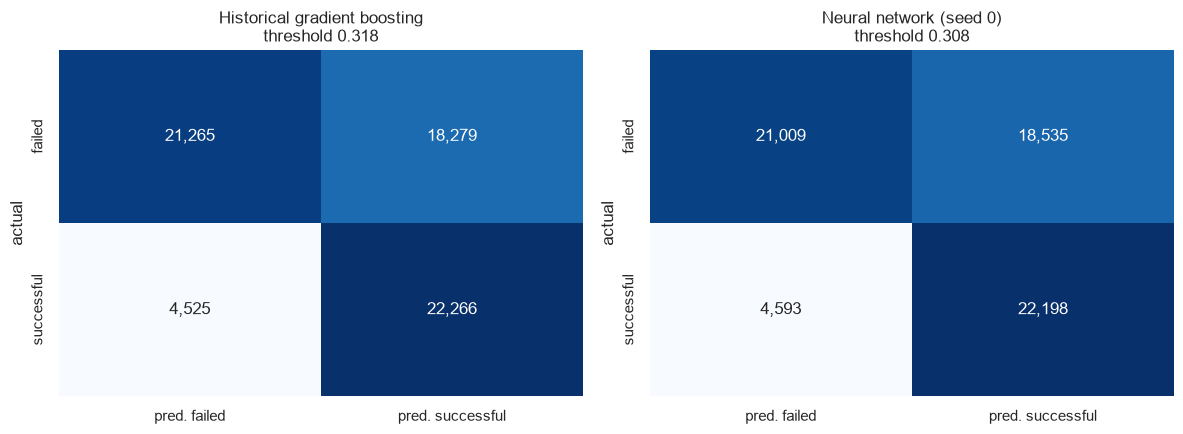

,false_hope_total,confident_false_hope_p>=0.7,missed_successes
model,,,
Historical gradient boosting,18279,1832,4525
Neural network (seed 0),18535,1970,4593


In [10]:
median_seed = nn_aucs.sort_values().index[len(nn_aucs) // 2]
rep_seed = int(median_seed.split("seed ")[1].rstrip(")"))
nn_rep_proba, nn_rep_threshold = seed_test_proba[rep_seed], nn_seeds.loc[median_seed, "threshold"]
print(f"Representative network: seed {rep_seed}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (title, proba, thr) in zip(axes, [
    ("Historical gradient boosting", hgb_test_proba, hgb_threshold),
    (f"Neural network (seed {rep_seed})", nn_rep_proba, nn_rep_threshold),
]):
    cm = confusion_matrix(y_test, (proba >= thr).astype(int))
    sns.heatmap(cm, annot=True, fmt=",", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["pred. failed", "pred. successful"], yticklabels=["failed", "successful"])
    ax.set(title=f"{title}\nthreshold {thr:.3f}", xlabel="", ylabel="actual")
plt.tight_layout()
plt.show()

errors = pd.DataFrame({
    "model": ["Historical gradient boosting", f"Neural network (seed {rep_seed})"],
    "false_hope_total": [((hgb_test_proba >= hgb_threshold) & (y_arr == 0)).sum(),
                         ((nn_rep_proba >= nn_rep_threshold) & (y_arr == 0)).sum()],
    "confident_false_hope_p>=0.7": [((hgb_test_proba >= 0.7) & (y_arr == 0)).sum(),
                                    ((nn_rep_proba >= 0.7) & (y_arr == 0)).sum()],
    "missed_successes": [((hgb_test_proba < hgb_threshold) & (y_arr == 1)).sum(),
                         ((nn_rep_proba < nn_rep_threshold) & (y_arr == 1)).sum()],
}).set_index("model")
errors

In [11]:
# The five most confident false-hope cases of the network, with the baseline's view of the same campaigns
false_hope = X_test.assign(success=y_arr, nn_proba=nn_rep_proba, hgb_proba=hgb_test_proba)
(false_hope[false_hope["success"] == 0]
 .nlargest(5, "nn_proba")
 [["main_category", "category", "country", "usd_goal_real", "duration_days", "launch_year", "nn_proba", "hgb_proba"]]
 .round(3))

,main_category,category,country,usd_goal_real,duration_days,launch_year,nn_proba,hgb_proba
298161,Games,Tabletop Games,US,20.0,9,2016,0.937,0.978
94731,Games,Tabletop Games,US,250.0,10,2017,0.932,0.933
329271,Games,Tabletop Games,US,150.0,7,2017,0.931,0.950
78074,Games,Tabletop Games,US,500.0,16,2016,0.919,0.905
50683,Games,Tabletop Games,US,15000.0,16,2016,0.917,0.907


## Probability Quality (Calibration)

The product shows creators a **probability**, so "60%" must mean that about 60% of such campaigns succeed. A reliability curve plots predicted probability against the actual success rate; a perfect model lies on the diagonal. Neural networks are known to be over-confident sometimes, so we check rather than assume. Lower **Brier score** and **log loss** mean better probabilities.

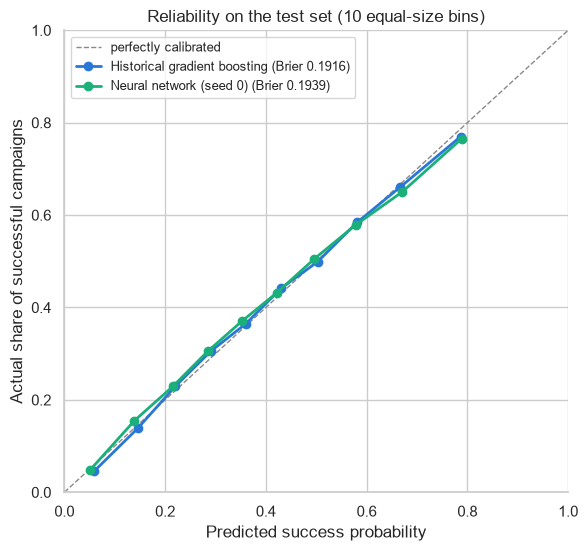

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], color=NEUTRAL_COLOR, linestyle="--", linewidth=1, label="perfectly calibrated")
for label, proba, color in [("Historical gradient boosting", hgb_test_proba, SUCCESS_COLOR),
                            (f"Neural network (seed {rep_seed})", nn_rep_proba, NN_COLOR)]:
    frac_pos, mean_pred = calibration_curve(y_test, proba, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", color=color, linewidth=2,
            label=f"{label} (Brier {brier_score_loss(y_test, proba):.4f})")
ax.set(title="Reliability on the test set (10 equal-size bins)", xlabel="Predicted success probability",
       ylabel="Actual share of successful campaigns", xlim=(0, 1), ylim=(0, 1))
ax.legend(loc="upper left", fontsize=9)
plt.show()

## Subgroups: Where Does Each Model Win?

An overall average can hide segments where a model is much worse. We compare ROC-AUC by main category, goal size and launch year.

In [13]:
goal_bins = [0, 1_000, 2_500, 5_000, 10_000, 25_000, 50_000, np.inf]
goal_labels = ["< $1k", "$1k-2.5k", "$2.5k-5k", "$5k-10k", "$10k-25k", "$25k-50k", "> $50k"]
segments = X_test.assign(
    success=y_arr, hgb=hgb_test_proba, nn=nn_mean_proba,
    goal_bucket=pd.cut(X_test["usd_goal_real"], goal_bins, labels=goal_labels, right=False),
)


def segment_auc(column):
    rows = []
    for value, g in segments.groupby(column, observed=True):
        if g["success"].nunique() < 2 or len(g) < 200:
            continue
        hgb_s, nn_s = roc_auc_score(g["success"], g["hgb"]), roc_auc_score(g["success"], g["nn"])
        rows.append({column: value, "projects": len(g), "hgb_roc_auc": hgb_s, "nn_roc_auc": nn_s, "nn_minus_hgb": nn_s - hgb_s})
    return pd.DataFrame(rows).set_index(column).round(4)


for column in ["main_category", "goal_bucket", "launch_year"]:
    display(segment_auc(column).sort_values("nn_minus_hgb"))

,projects,hgb_roc_auc,nn_roc_auc,nn_minus_hgb
main_category,,,,
Journalism,837,0.7623,0.7350,-0.0273
Publishing,7094,0.7257,0.7096,-0.0161
Design,5057,0.7121,0.7024,-0.0097
Dance,771,0.6750,0.6665,-0.0085
Games,5618,0.8050,0.7972,-0.0078
Art,5293,0.7275,0.7207,-0.0068
Theater,2086,0.7145,0.7081,-0.0064
Technology,5349,0.8309,0.8277,-0.0031
Food,4438,0.7548,0.7545,-0.0003


,projects,hgb_roc_auc,nn_roc_auc,nn_minus_hgb
goal_bucket,,,,
$25k-50k,5509,0.7593,0.7523,-0.0071
$2.5k-5k,10253,0.7343,0.7275,-0.0068
> $50k,5754,0.8268,0.8205,-0.0064
$10k-25k,13241,0.7413,0.7361,-0.0052
$5k-10k,12448,0.7329,0.7280,-0.0049
$1k-2.5k,10325,0.7304,0.7276,-0.0028
< $1k,8805,0.7138,0.7156,0.0018


,projects,hgb_roc_auc,nn_roc_auc,nn_minus_hgb
launch_year,,,,
2017,8652,0.7757,0.7704,-0.0052
2016,9653,0.7823,0.7777,-0.0046
2013,8205,0.7238,0.7197,-0.0041
2012,7750,0.7345,0.7308,-0.0037
2011,4801,0.7177,0.7140,-0.0037
2009,237,0.6201,0.6168,-0.0033
2014,11973,0.7653,0.7624,-0.0029
2015,13170,0.7857,0.7832,-0.0025
2010,1894,0.6700,0.6691,-0.0009


## Logical What-If Advice (Monotonic Goal)

The creator tool lets users change their goal and see the new chance. The baseline has a **monotonic constraint**: a higher goal can never raise the chance. The network has no such built-in rule. We test 1,000 random test campaigns, try 25 goals from \$500 to \$200,000, and count how often a higher goal *raises* the predicted chance by more than one percentage point.

In [14]:
check = X_test.sample(200 if SMOKE_TEST else 1000, random_state=RANDOM_STATE)
goal_grid = np.geomspace(500, 200_000, 25)
grid_rows = check.loc[check.index.repeat(len(goal_grid))].copy()
grid_rows["usd_goal_real"] = np.tile(goal_grid, len(check))
grid_rows["log_goal"] = np.log1p(grid_rows["usd_goal_real"])

curves = {
    "Historical gradient boosting": hgb.predict_proba(grid_rows[FEATURES])[:, 1],
    f"Neural network (seed {rep_seed})": seed_models[rep_seed].predict(prep.transform(grid_rows), batch_size=8192, verbose=0).ravel(),
}
monotonic_rows = []
for label, proba in curves.items():
    steps = np.diff(proba.reshape(len(check), len(goal_grid)), axis=1)
    monotonic_rows.append({
        "model": label,
        "campaigns_with_any_rise_>1pp": (steps > 0.01).any(axis=1).mean(),
        "largest_rise_pp": 100 * steps.max(),
    })
pd.DataFrame(monotonic_rows).set_index("model").round(4)

,campaigns_with_any_rise_>1pp,largest_rise_pp
model,,
Historical gradient boosting,0.000,0.0000
Neural network (seed 0),0.116,4.3908


## System Trade-Offs: Time, Latency and Size

All measurements run on the same laptop, in the same session. Latency is measured end to end (preprocessing plus model) for:

- a **batch** of all 66,335 test campaigns (offline scoring), and
- a **single campaign**, as in the interactive what-if tool. For the network we call the model directly (`model(inputs)`), the usual way to serve single predictions in Keras.

3 warm-up calls are discarded, then 20 timed calls; we report the median and the 95th percentile.

In [15]:
def time_it(fn):
    for _ in range(TIMING_WARMUP):
        fn()
    times = []
    for _ in range(TIMING_REPEATS):
        start = time.perf_counter()
        fn()
        times.append(time.perf_counter() - start)
    return np.median(times) * 1000, np.percentile(times, 95) * 1000


nn_rep = seed_models[rep_seed]
one_row = X_test[FEATURES].iloc[[0]]
latency = {
    "Historical gradient boosting": {
        "batch": time_it(lambda: hgb.predict_proba(X_test[FEATURES])),
        "single": time_it(lambda: hgb.predict_proba(one_row)),
    },
    "Neural network": {
        "batch": time_it(lambda: nn_rep.predict(prep.transform(X_test), batch_size=8192, verbose=0)),
        "single": time_it(lambda: nn_rep(prep.transform(one_row), training=False)),
    },
}

nn_rep.save(NN_PATH)
joblib.dump(prep, NN_PREP_PATH)
size_mb = lambda *paths: sum(p.stat().st_size for p in paths) / 1e6

system = pd.DataFrame({
    "Historical gradient boosting": {
        "final_fit_seconds": hgb_fit_seconds,
        "tuning_effort": f"12 configs x 3-fold CV = 36 fits (~{36 * hgb_fit_seconds / 60:.0f} min estimated, not recorded)",
        "batch_66k_median_ms": latency["Historical gradient boosting"]["batch"][0],
        "batch_66k_p95_ms": latency["Historical gradient boosting"]["batch"][1],
        "throughput_rows_per_s": len(X_test) / latency["Historical gradient boosting"]["batch"][0] * 1000,
        "single_median_ms": latency["Historical gradient boosting"]["single"][0],
        "single_p95_ms": latency["Historical gradient boosting"]["single"][1],
        "artifact_mb": size_mb(HGB_REBUILT_PATH),
        "parameters": "1,000 trees x up to 63 leaves",
    },
    "Neural network": {
        "final_fit_seconds": seed_fit_seconds[rep_seed],
        "tuning_effort": f"{N_TRIALS} configs, {trials['epochs'].sum()} epochs, {search_seconds / 60:.1f} min measured "
                         f"+ {len(SEEDS)} seeds, {sum(seed_fit_seconds.values()) / 60:.1f} min",
        "batch_66k_median_ms": latency["Neural network"]["batch"][0],
        "batch_66k_p95_ms": latency["Neural network"]["batch"][1],
        "throughput_rows_per_s": len(X_test) / latency["Neural network"]["batch"][0] * 1000,
        "single_median_ms": latency["Neural network"]["single"][0],
        "single_p95_ms": latency["Neural network"]["single"][1],
        "artifact_mb": size_mb(NN_PATH, NN_PREP_PATH),
        "parameters": f"{nn_rep.count_params():,} weights",
    },
})
system

,Historical gradient boosting,Neural network
final_fit_seconds,22.987315,131.214363
tuning_effort,12 configs x 3-fold CV = 36 fits (~14 min esti...,"12 configs, 359 epochs, 12.1 min measured + 5 ..."
batch_66k_median_ms,2286.9656,431.3245
batch_66k_p95_ms,2435.1308,541.699625
throughput_rows_per_s,29005.683339,153793.721429
single_median_ms,12.54395,16.8004
single_p95_ms,15.581645,21.979445
artifact_mb,3.13262,1.931672
parameters,"1,000 trees x up to 63 leaves","153,923 weights"


## Summary for the Report

The numbers below feed [`model-comparison-report.md`](model-comparison-report.md) and [`decision-memo.md`](decision-memo.md).

In [16]:
print(f"Best network configuration: {best_cfg}")
print(f"Baseline ROC-AUC {hgb_auc:.5f} | network mean {nn_aucs.mean():.5f} (std {nn_aucs.std():.5f})")
print(f"Difference mean {diff_mean:+.5f}, worst seed {diff_worst:+.5f}, bootstrap 95% [{ci_low:+.5f}, {ci_high:+.5f}]")
print(f"Brier: baseline {brier_score_loss(y_test, hgb_test_proba):.5f}, "
      f"network mean {nn_seeds['brier'].mean():.5f}")
print("Practical difference reached:", diff_mean >= PRACTICAL_DIFFERENCE and diff_worst >= PRACTICAL_DIFFERENCE)

Best network configuration: {'width': 256, 'depth': 3, 'dropout': 0.1, 'l2': 0.0001, 'emb_dim': 16, 'batch_size': 1024, 'learning_rate': 0.000582705823829026}
Baseline ROC-AUC 0.76523 | network mean 0.75895 (std 0.00073)
Difference mean -0.00628, worst seed -0.00755, bootstrap 95% [-0.00479, -0.00213]
Brier: baseline 0.19159, network mean 0.19405
Practical difference reached: False
